# **Reading Data**

In [1]:
import os,cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split
import tensorflow.keras.backend as K
# from keras.utils import np_utils

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import os
import cv2
import numpy as np

data_path = '/content/drive/MyDrive/Colorectal_tissue_dataset/CRC-VAL-HE-7K'
data_dir_list = ['ADI', 'BACK', 'DEB', 'LYM', 'MUC', 'MUS', 'NORM', 'STR', 'TUM']

folder_mapping = {
    'ADI': '0',
    'BACK': '1',
    'DEB': '2',
    'LYM': '3',
    'MUC': '4',
    'MUS': '5',
    'NORM': '6',
    'STR': '7',
    'TUM': '8'
}

img_data_list = []
labels = []
image_count = {folder: 0 for folder in data_dir_list}

for dataset in data_dir_list:
    img_list = os.listdir(os.path.join(data_path, dataset))
    print('Loaded the images of dataset-{}'.format(folder_mapping[dataset]))
    print()
    for img in img_list:
        input_img = cv2.imread(os.path.join(data_path, dataset, img))
        if input_img is None:
            continue  # skip if the image is not loaded correctly

        labels.append(folder_mapping[dataset])
        input_img_resize = cv2.resize(input_img, (128, 128))
        img_data_list.append(input_img_resize)
        image_count[dataset] += 1  # increment the count for this folder

label = np.array(labels)
data = np.array(img_data_list)

data = data.astype('float32')
data = data / 255.0

# Print the shape of the data
print("Data shape:", data.shape)

# Print the count of images in each folder
# for folder, count in image_count.items():
#     print(f'There are {count} images in the folder labeled as {folder_mapping[folder]}')


Loaded the images of dataset-0

Loaded the images of dataset-1

Loaded the images of dataset-2

Loaded the images of dataset-3

Loaded the images of dataset-4

Loaded the images of dataset-5

Loaded the images of dataset-6

Loaded the images of dataset-7

Loaded the images of dataset-8

Data shape: (7180, 128, 128, 3)


In [4]:
num_classes = 9
from tensorflow.keras.utils import to_categorical
Y = to_categorical(label, num_classes)
x,y = shuffle(data,Y, random_state= 2)
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size = 0.1, random_state = 2)
print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of y_test:", y_test.shape)

Shape of X_train: (6462, 128, 128, 3)
Shape of X_test: (718, 128, 128, 3)
Shape of y_train: (6462, 9)
Shape of y_test: (718, 9)


In [5]:
X_train = X_train.reshape(-1,128,128, 3)
X_test = X_test.reshape(-1, 128, 128, 3)

# **Original Feature Distrubution**

In [9]:
import numpy as np
import pandas as pd
x = X_test.reshape(718, -1)
np.savetxt('/content/drive/MyDrive/feature_files/ct_dataset_2_X_test.csv', x, delimiter = ",")

q =  np.argmax(y_test, axis =1).reshape(718, -1)
np.save('q.npy', q)
k = np.load('q.npy')
np.savetxt("/content/drive/MyDrive/feature_files/ct_dataset_2_y_test.csv", k,  delimiter = ",")

In [5]:
import pandas as pd
df = pd.read_csv("/content/drive/MyDrive/feature_files/ct_dataset_2_X_test.csv", header = None, delimiter = ",")
df.head()

,0,1,2,3,4,5,6,7,8,9,...,49142,49143,49144,49145,49146,49147,49148,49149,49150,49151
0,0.556863,0.329412,0.525490,0.552941,0.333333,0.517647,0.572549,0.360784,0.509804,0.572549,...,0.525490,0.572549,0.360784,0.509804,0.572549,0.360784,0.509804,0.572549,0.360784,0.509804
1,0.968627,0.949020,0.972549,0.929412,0.886275,0.933333,0.862745,0.760784,0.925490,0.843137,...,0.768627,0.607843,0.400000,0.611765,0.592157,0.356863,0.600000,0.529412,0.298039,0.564706
2,0.694118,0.419608,0.776471,0.721569,0.423529,0.749020,0.596078,0.372549,0.670588,0.662745,...,0.576471,0.694118,0.333333,0.670588,0.678431,0.325490,0.639216,0.658824,0.309804,0.643137
3,0.631373,0.427451,0.705882,0.733333,0.529412,0.831373,0.788235,0.662745,0.870588,0.709804,...,0.709804,0.643137,0.443137,0.858824,0.650980,0.443137,0.800000,0.607843,0.400000,0.815686
4,0.682353,0.490196,0.772549,0.729412,0.572549,0.819608,0.749020,0.588235,0.823529,0.717647,...,0.615686,0.623529,0.407843,0.721569,0.733333,0.549020,0.819608,0.874510,0.772549,0.921569


In [6]:
import numpy as np
from sklearn.manifold import TSNE
X = np.array(df)
X_embedded = TSNE(n_components=2).fit_transform(X)

In [7]:
df1 = pd.read_csv("/content/drive/MyDrive/feature_files/ct_dataset_2_y_test.csv", header = None,  delimiter = ",")
df1.head()

,0
0,1.0
1,3.0
2,7.0
3,8.0
4,6.0


In [9]:
import plotly.express as px
fig = px.scatter(X_embedded, x =0, y = 1, color=df1[0], width=600, height=500)
fig.show()

In [24]:
import matplotlib.pyplot as plt

# Assuming X_embedded is a DataFrame with columns named 0 and 1
# Assuming df1 is a DataFrame and the color array is in its first column

# Check the lengths of the arrays
if len(X_embedded[0]) == len(X_embedded[1]) == len(df1[0]):
    # Create the scatter plot
    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(X_embedded[0], X_embedded[1], c=df1[0], cmap='viridis')  # Added colormap
    plt.xlabel('0')
    plt.ylabel('1')
    plt.title('Original Feature Distribution')
    plt.colorbar(scatter, label='Label')
    plt.tight_layout()

    # Save the figure to PDF
    pdf_file_path = "/content/drive/MyDrive/ct2_scatter_plot.pdf"
    plt.savefig(pdf_file_path, format='pdf')

    # Display the path to the saved PDF file
    print("Figure saved to:", pdf_file_path)
else:
    print("Error: The lengths of X_embedded[0], X_embedded[1], and df1[0] are not the same.")


Error: The lengths of X_embedded[0], X_embedded[1], and df1[0] are not the same.


ValueError: 'c' argument has 718 elements, which is inconsistent with 'x' and 'y' with size 2.

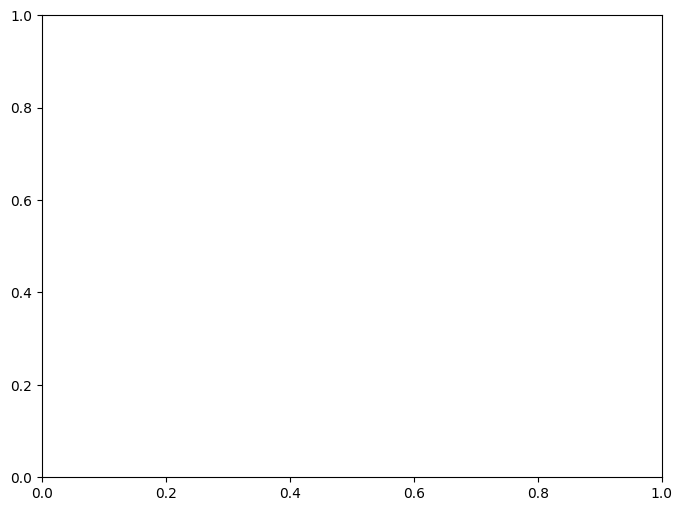

In [18]:
import matplotlib.pyplot as plt

# Create the scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(X_embedded[0], X_embedded[1], c=df1[0])  # Use integer indices
plt.xlabel('0')
plt.ylabel('1')
plt.title('Original Feature Distribution')
plt.colorbar(label='Label')
# plt.grid(True)
plt.tight_layout()

# Save the figure to PDF
pdf_file_path = "/content/drive/MyDrive/ct2_scatter_plot.pdf"
plt.savefig(pdf_file_path, format='pdf')

# Display the path to the saved PDF file
print("Figure saved to:", pdf_file_path)


# **Reshaping the Data**

In [ ]:
X_train = X_train.reshape(-1, 128, 128, 3)
X_test = X_test.reshape(-1, 128, 128, 3)
X_train.shape

(6462, 128, 128, 3)

# **Network**

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import sys,os,cv2
import tensorflow as tf
from keras.layers import Conv2D, Add, MaxPooling2D, AveragePooling2D, Activation, Dense, PReLU, Layer
from keras.layers import Input, BatchNormalization, GlobalAveragePooling2D, Concatenate, Cropping2D, Multiply, Lambda, Flatten, Reshape
from keras.activations import relu, softmax, sigmoid, tanh
from keras import initializers
from keras.models import Model
from keras.regularizers import l2
import h5py

from sklearn.metrics import accuracy_score
from tensorflow import keras
from tensorflow.keras.utils import to_categorical
from keras.callbacks import ReduceLROnPlateau, ModelCheckpoint
from keras.models import load_model, Model

In [ ]:
# class DepthwiseSeparableConv2D(keras.layers.Layer):
#     def __init__(self, filters, kernel_size, padding, activation):
#         super(DepthwiseSeparableConv2D, self).__init__()
#         self.depthwise = DepthwiseConv2D(kernel_size = kernel_size, padding = padding, activation = activation)
#         self.pointwise = Conv2D(filters = filters, kernel_size = (1, 1), activation = activation)
#     def call(self, input_tensor):
#         x = self.depthwise(input_tensor)
#         return self.pointwise(x)

In [ ]:
from keras import backend as K
def Cosin_similarity(input):
    dot1 = K.batch_dot(input[0], input[1], axes=[1, 1])
    dot2 = K.batch_dot(input[0], input[0], axes=[1, 1])
    dot3 = K.batch_dot(input[1], input[1], axes=[1, 1])
    max = K.maximum(K.sqrt(dot2 * dot3), K.epsilon())
    value = dot1 / max
    return K.tanh(value)

In [ ]:
def Bund(input):
    alpha_1 = input[0]
    alpha_2 = input[1]

    alpha_l = alpha_1/(alpha_1+alpha_2)
    alpha_g = alpha_2/(alpha_1+alpha_2)

    return alpha_l, alpha_g

In [ ]:
# import keras
# # from keras.applications import EfficientNetB0, ResNet50, VGG16, InceptionV3
# from keras.layers import Dense, GlobalAveragePooling2D, Conv2D, Flatten, Add, Activation, Input, MaxPooling2D, SeparableConv2D
# from tensorflow.keras.optimizers import RMSprop, Adam, Nadam
# from keras import regularizers
# from keras.models import Model
# def Enhance_Net(eps = 1.1e-5):
#     input1 = Input((19, 1024, 1))
#     x1 = SeparableConv2D(filters=32, kernel_size=(1, 3), padding = 'same', activation='relu')(input1)
#     x1 = BatchNormalization(axis=-1, epsilon=eps)(x1)
#     x2 = SeparableConv2D(filters=32, kernel_size=(1, 3), padding = 'same', activation='relu')(x1)
#     x2 = BatchNormalization(axis=-1, epsilon=eps)(x2)
#     x3 = SeparableConv2D(filters=32, kernel_size=(1, 3), padding = 'same', activation='relu')(x2)
#     x3 = BatchNormalization(axis=-1, epsilon=eps)(x3)
#     c1 = Concatenate()([x1, x2, x3])
#     c1 = SeparableConv2D(128, (1, 1), padding = 'same', activation = 'relu')(c1)
#     c1 = BatchNormalization(axis=-1, epsilon=eps)(c1)
#     c1 = MaxPooling2D(pool_size=(1, 2), strides=(1, 2), padding='same')(c1)

#     x11 = Conv2D(128, (1, 3), dilation_rate = 1, padding = 'same', activation = 'relu')(c1)
#     x11 = BatchNormalization(axis=-1, epsilon=eps)(x11)
#     x12 = Conv2D(128, (1, 3), dilation_rate = 2, padding = 'same', activation = 'relu')(c1)
#     x12 = BatchNormalization(axis=-1, epsilon=eps)(x12)
#     x13 = Conv2D(128, (1, 3), dilation_rate = 3, padding = 'same', activation = 'relu')(c1)
#     x13 = BatchNormalization(axis=-1, epsilon=eps)(x13)
#     M1 = Multiply()([x11, x12])
#     M2 = Multiply()([x11, x13])
#     M3 = Multiply()([x12, x13])
#     x21 = Conv2D(128, (1, 3), dilation_rate = 1, padding = 'same', activation = 'relu')(M1)
#     x21 = BatchNormalization(axis=-1, epsilon=eps)(x21)
#     x22 = Conv2D(128, (1, 3), dilation_rate = 2, padding = 'same', activation = 'relu')(M2)
#     x22 = BatchNormalization(axis=-1, epsilon=eps)(x22)
#     x23 = Conv2D(128, (1, 3), dilation_rate = 3, padding = 'same', activation = 'relu')(M3)
#     x23 = BatchNormalization(axis=-1, epsilon=eps)(x23)
#     M4 = Multiply()([x21, x22, x23])
#     x31 = Conv2D(128, (1,1), padding = 'same', activation = 'relu')(M4)
#     A1 = Add()([x31, c1])



#     x4 = SeparableConv2D(filters=64, kernel_size=(1, 3), padding = 'same', activation='relu')(x3)
#     x4 = BatchNormalization(axis=-1, epsilon=eps)(x4)
#     x5 = SeparableConv2D(filters=64, kernel_size=(1, 3), padding = 'same', activation='relu')(x4)
#     x5 = BatchNormalization(axis=-1, epsilon=eps)(x5)
#     c2 = Concatenate()([x4, x5])
#     c2 = SeparableConv2D(128, (1, 1), padding = 'same', activation = 'relu')(c2)
#     c2 = BatchNormalization(axis=-1, epsilon=eps)(c2)
#     c2 = MaxPooling2D(pool_size=(1, 2), strides=(1, 2), padding='same')(c2)

#     x41 = Conv2D(128, (1, 3), dilation_rate = 1, padding = 'same', activation = 'relu')(c2)
#     x41 = BatchNormalization(axis=-1, epsilon=eps)(x41)
#     x42 = Conv2D(128, (1, 3), dilation_rate = 2, padding = 'same', activation = 'relu')(c2)
#     x42 = BatchNormalization(axis=-1, epsilon=eps)(x42)
#     x43 = Conv2D(128, (1, 3), dilation_rate = 3, padding = 'same', activation = 'relu')(c2)
#     x43 = BatchNormalization(axis=-1, epsilon=eps)(x43)
#     M5 = Multiply()([x41, x42])
#     M6 = Multiply()([x41, x43])
#     M7 = Multiply()([x42, x43])
#     x51 = Conv2D(128, (1, 3), dilation_rate = 1, padding = 'same', activation = 'relu')(M5)
#     x51 = BatchNormalization(axis=-1, epsilon=eps)(x51)
#     x52 = Conv2D(128, (1, 3), dilation_rate = 2, padding = 'same', activation = 'relu')(M6)
#     x52 = BatchNormalization(axis=-1, epsilon=eps)(x52)
#     x53 = Conv2D(128, (1, 3), dilation_rate = 3, padding = 'same', activation = 'relu')(M7)
#     x53 = BatchNormalization(axis=-1, epsilon=eps)(x53)
#     M8 = Multiply()([x51, x52, x53])
#     x61 = Conv2D(128, (1,1), padding = 'same', activation = 'relu')(M8)
#     A2 = Add()([x61, c2])

#     x_lg = Multiply()([A1, A2])
#     x_gl = Add()([A1, A2])
#     x_c = Concatenate()([x_lg, x_gl])

#     x_c = GlobalAveragePooling2D()(x_c)
#     x_l = GlobalAveragePooling2D()(A1)
#     x_g = GlobalAveragePooling2D()(A2)

#     x_l = Dense(units= 256, activation=relu)(x_l)
#     x_g = Dense(units= 256, activation=relu)(x_g)
#     share_1 = Dense(units=512, activation=relu)
#     share_2 = Dense(units=512, activation=relu)
#     x_l = share_1(x_l)
#     x_g = share_1(x_g)
#     x_c = share_1(x_c)
#     x_l = share_2(x_l)
#     x_g = share_2(x_g)
#     x_c = share_2(x_c)

#     alpha_1 = Lambda(Cosin_similarity)([x_l, x_c])
#     alpha_2 = Lambda(Cosin_similarity)([x_c, x_c])
#     alpha_l, alpha_g = Lambda(Bund)([alpha_1, alpha_2])
#     out_l = Multiply()([alpha_l, x_l])
#     out_g = Multiply()([alpha_g, x_c])

#     out = Concatenate()([out_l, out_g])
#     out = Dense(units=2, activation= 'sigmoid')(out)
#     model = Model([input1], [out])
#     return model

# model = Enhance_Net(eps = 1.1e-5)
# opt = Nadam(learning_rate=0.0001)
# model.compile(optimizer=opt, loss=['categorical_crossentropy'], metrics=['acc'])
# model.summary()

In [ ]:
#spatial attention
def residual_csa_module(input_tensor, reduction_ratio=16):
    channels = input_tensor.shape[-1]

    # Convolutional layer for feature extraction
    conv1 = Conv2D(filters=channels // reduction_ratio, kernel_size=(1, 1), padding='same', activation='relu')(input_tensor)
    conv2 = Conv2D(filters=channels // reduction_ratio, kernel_size=(1, 1), padding='same', activation='relu')(conv1)
    conv3 = Conv2D(filters=channels, kernel_size=(1, 1), padding='same', activation='relu')(conv2)

    # Spatial attention mechanism
    attention_map = Conv2D(filters=1, kernel_size=(1, 1), padding='same', activation='sigmoid')(conv3)

    # Multiply attention map with input tensor
    attention = Multiply()([attention_map, input_tensor])

    # Residual connection
    output = Add()([attention, input_tensor])

    return output

In [ ]:
#channel attention
def eca_module(input_tensor, gamma=2, b=1):
    channels = input_tensor.shape[-1]
    print(channels)

    squeeze = GlobalAveragePooling2D()(input_tensor)
    excitation = Dense(units=channels // gamma)(squeeze)
    excitation = Activation('relu')(excitation)
    excitation = Dense(units=channels)(excitation)
    excitation = Activation('sigmoid')(excitation)
    excitation = Reshape((1, 1, channels))(excitation)

    scale = Multiply()([input_tensor, excitation])

    output = Add()([scale, input_tensor])
    return output

In [ ]:
from keras.models import Model
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.optimizers import RMSprop, Adam, Nadam
from keras.layers import Input, Conv2D, LSTM, Add, Multiply, Concatenate, MaxPooling2D, AveragePooling2D, Flatten, Lambda
from keras.layers import SeparableConv2D, MaxPooling2D, Flatten, Dense, GlobalAveragePooling2D, GlobalMaxPooling2D, BatchNormalization
eps = 1.1e-5
input1 = Input((128, 128, 3))

x1 = Conv2D(64, (3, 3), padding = 'same', activation='relu')(input1)
x1 = BatchNormalization(axis=-1, epsilon=eps)(x1)
x2 = Conv2D(64, (3, 3), padding = 'same', activation='relu')(x1)
x2 = BatchNormalization(axis=-1, epsilon=eps)(x2)
x3 = Conv2D(64, (3, 3), padding = 'same', activation='relu')(x2)
x3 = BatchNormalization(axis=-1, epsilon=eps)(x3)
c1 = Concatenate()([x1, x2, x3])

x11 = Conv2D(192, (3,3), dilation_rate = (1, 1), padding = 'same', activation='relu')(c1)
x11 = BatchNormalization(axis=-1, epsilon=eps)(x11)
x21 = Conv2D(192, (3,3), dilation_rate = (2, 2), padding = 'same', activation='relu')(c1)
x21 = BatchNormalization(axis=-1, epsilon=eps)(x21)
x31 = Conv2D(192, (3,3), dilation_rate = (3, 3) , padding = 'same', activation='relu')(c1)
x31 = BatchNormalization(axis=-1, epsilon=eps)(x31)
M1 = Multiply()([x11, x21])
M2 = Multiply()([x11, x31])
M3 = Multiply()([x21, x31])
x111 = Conv2D(192, (3,3),dilation_rate = (1, 1), padding = 'same', activation='relu')(M1)
x111 = BatchNormalization(axis=-1, epsilon=eps)(x111)
x211 = Conv2D(192, (3,3),dilation_rate = (2, 2), padding = 'same', activation='relu')(M2)
x211 = BatchNormalization(axis=-1, epsilon=eps)(x211)
x311 = Conv2D(192, (3,3),dilation_rate = (3, 3), padding = 'same', activation='relu')(M3)
x311 = BatchNormalization(axis=-1, epsilon=eps)(x311)
M4 = Multiply()([x111, x211, x311])
X44 = Conv2D(192, (1,1), padding = 'same', activation='relu')(M4)
X44 = BatchNormalization(axis=-1, epsilon=eps)(X44)
A1 = Add()([X44, c1])

#spatial attention
res_csa_module1 = residual_csa_module(A1)

x4 = Conv2D(64, (3, 3), padding = 'same', activation='relu')(x3)
x4 = BatchNormalization(axis=-1, epsilon=eps)(x4)
x5 = Conv2D(64, (3, 3), padding = 'same', activation='relu')(x4)
x5 = BatchNormalization(axis=-1, epsilon=eps)(x5)
x6 = Conv2D(64, (3, 3), padding = 'same', activation='relu')(x5)
x6 = BatchNormalization(axis=-1, epsilon=eps)(x6)
c2 = Concatenate()([x4, x5, x6])

x51 = Conv2D(192, (3,3), dilation_rate = (1, 1), padding = 'same', activation='relu')(c2)
x51 = BatchNormalization(axis=-1, epsilon=eps)(x51)
x61 = Conv2D(192, (3,3),dilation_rate = (2, 2), padding = 'same', activation='relu')(c2)
x61 = BatchNormalization(axis=-1, epsilon=eps)(x61)
x71 = Conv2D(192, (3,3),dilation_rate = (3, 3), padding = 'same', activation='relu')(c2)
x71 = BatchNormalization(axis=-1, epsilon=eps)(x71)
M6 = Multiply()([x51, x61])
M7 = Multiply()([x51, x71])
M8 = Multiply()([x61, x71])
x511 = Conv2D(192, (3,3), dilation_rate = (1, 1), padding = 'same', activation='relu')(M6)
x511 = BatchNormalization(axis=-1, epsilon=eps)(x511)
x611 = Conv2D(192, (3,3),dilation_rate = (2, 2), padding = 'same', activation='relu')(M7)
x611 = BatchNormalization(axis=-1, epsilon=eps)(x611)
x711 = Conv2D(192, (3,3), dilation_rate = (3, 3),padding = 'same', activation='relu')(M8)
x711 = BatchNormalization(axis=-1, epsilon=eps)(x711)
M9 = Multiply()([x511, x611, x711])
X81 = Conv2D(192, (1,1), padding = 'same', activation='relu')(M9)
X81 = BatchNormalization(axis=-1, epsilon=eps)(X81)
A2 = Add()([X81, c2])

#channel attention
eca_module1 = eca_module(A2)

x_l = A1
x_g = A2

# x_lg = Multiply()([A1, A2])
# x_gl = Add()([A1, A2])
x_c = Concatenate()([x_l, x_g])

x_l = GlobalAveragePooling2D()(x_l)
x_g = GlobalAveragePooling2D()(x_g)
x_c = GlobalAveragePooling2D()(x_c)

x_l = Dense(units=384, activation='relu')(x_l)
x_g = Dense(units=384, activation='relu')(x_g)

share_1 = Dense(units=768, activation='relu')
share_2 = Dense(units=768, activation='relu')

x_l = share_1(x_l)
x_g = share_1(x_g)
x_c = share_1(x_c)

x_l = share_2(x_l)
x_g = share_2(x_g)
x_c = share_2(x_c)

alpha_1 = Lambda(Cosin_similarity, output_shape= (None, 1))([x_l, x_c])
alpha_2 = Lambda(Cosin_similarity, output_shape= (None, 1))([x_g, x_c])
alpha_l, alpha_g = Lambda(Bund)([alpha_1, alpha_2])
out_l = Multiply()([alpha_l, x_l])
out_g = Multiply()([alpha_g, x_g])

out = Concatenate()([out_l, out_g])
out = Dense(units = 64, activation = 'relu')(out)

out = Dense(units=9, activation="softmax")(out)
model = Model(inputs=input1, outputs=out)
opt = Nadam(learning_rate=0.0001)
model.compile(optimizer= opt, loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

192
Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 128, 128, 3)]        0         []                            
                                                                                                  
 conv2d (Conv2D)             (None, 128, 128, 64)         1792      ['input_1[0][0]']             
                                                                                                  
 batch_normalization (Batch  (None, 128, 128, 64)         256       ['conv2d[0][0]']              
 Normalization)                                                                                   
                                                                                                  
 conv2d_1 (Conv2D)           (None, 128, 128, 64)         36928     ['batch_normalization[

# **Training Model**

In [ ]:
# model.compile(optimizer= Adam(learning_rate=0.0001, weight_decay = 1e-5), loss='categorical_crossentropy', metrics=['accuracy'])
from keras.callbacks import EarlyStopping, ModelCheckpoint
early_stopping = EarlyStopping(
                              patience=10,
                              min_delta=0.001,
                              monitor="val_accuracy",
                              restore_best_weights=True
                              )
# Define the model checkpoint callback to save the best weights
checkpoint = ModelCheckpoint('/content/drive/MyDrive/weight_files/Dataset_2'+'-{epoch:02d}.keras', monitor='val_accuracy', save_best_only=True)

history = model.fit(X_train, y_train, batch_size= 16, epochs= 50,
                    verbose=1, callbacks=[early_stopping, checkpoint], validation_data=(X_test, y_test), shuffle = True) #, callbacks=[early_stopping, checkpoint]

Epoch 1/50
404/404 [==============================] - 745s 2s/step - loss: 0.6548 - accuracy: 0.7900 - val_loss: 5.5165 - val_accuracy: 0.2702
Epoch 2/50
404/404 [==============================] - 691s 2s/step - loss: 0.2667 - accuracy: 0.9123 - val_loss: 0.6550 - val_accuracy: 0.7953
Epoch 3/50
404/404 [==============================] - 690s 2s/step - loss: 0.1882 - accuracy: 0.9331 - val_loss: 0.1541 - val_accuracy: 0.9387
Epoch 4/50
404/404 [==============================] - 690s 2s/step - loss: 0.1489 - accuracy: 0.9496 - val_loss: 0.1742 - val_accuracy: 0.9206
Epoch 5/50
404/404 [==============================] - 673s 2s/step - loss: 0.1265 - accuracy: 0.9590 - val_loss: 0.1929 - val_accuracy: 0.9457
Epoch 6/50
404/404 [==============================] - 691s 2s/step - loss: 0.1096 - accuracy: 0.9632 - val_loss: 1.4184 - val_accuracy: 0.7465
Epoch 7/50
404/404 [==============================] - 690s 2s/step - loss: 0.0975 - accuracy: 0.9684 - val_loss: 0.1159 - val_accuracy: 0.9735

# **Loading the Training Model**

In [12]:
import keras
from keras import backend as K

# Define the custom Cosin_similarity function
def Cosin_similarity(inputs):
    dot1 = K.batch_dot(inputs[0], inputs[1], axes=[1, 1])
    dot2 = K.batch_dot(inputs[0], inputs[0], axes=[1, 1])
    dot3 = K.batch_dot(inputs[1], inputs[1], axes=[1, 1])
    max_val = K.maximum(K.sqrt(dot2 * dot3), K.epsilon())
    value = dot1 / max_val
    return K.tanh(value)

# Load the model with custom objects
custom_objects = {'Cosin_similarity': Cosin_similarity}

model = keras.models.load_model('/content/drive/MyDrive/weight_files/Dataset_2-07.keras', custom_objects=custom_objects, safe_mode=False)

# Save the complete model (architecture + weights)
# model.save('/content/drive/MyDrive/weight_files/ct2_model.h5')

# **Model Prediction**

In [ ]:
loss, accuracy = model.evaluate(X_test, y_test)
print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

# Predicting the Test set results
pred = model.predict(X_test)
print("Y_pred:", pred)
print("*****************")
y_pred = np.argmax(pred, axis = 1)
y_true = np.argmax(y_test, axis = 1)

23/23 [==============================] - 2018s 87s/step - loss: 0.1159 - accuracy: 0.9735
Test Loss: 0.11592396348714828
Test Accuracy: 0.9735376238822937
23/23 [==============================] - 1965s 85s/step
Y_pred: [[2.47348519e-09 9.99991119e-01 1.80394224e-07 ... 6.46566889e-09
  3.03107157e-07 1.21697425e-08]
 [7.73146846e-16 9.45898308e-12 8.82480222e-08 ... 2.17159659e-08
  1.08074851e-11 7.89716570e-10]
 [6.59768484e-05 5.27442899e-05 1.24183549e-02 ... 1.87419297e-04
  9.49110329e-01 1.27107918e-03]
 ...
 [9.99269664e-01 1.36727891e-07 6.57155681e-07 ... 3.98518372e-04
  1.04618084e-05 1.72058659e-04]
 [6.51991385e-08 6.58163302e-09 8.57073914e-08 ... 7.21539345e-06
  4.43320096e-06 9.99987245e-01]
 [3.42565763e-05 3.04346668e-06 9.84757766e-03 ... 2.18372534e-05
  8.26132447e-02 3.04047862e-04]]
*****************


# **Confusion Matrix**

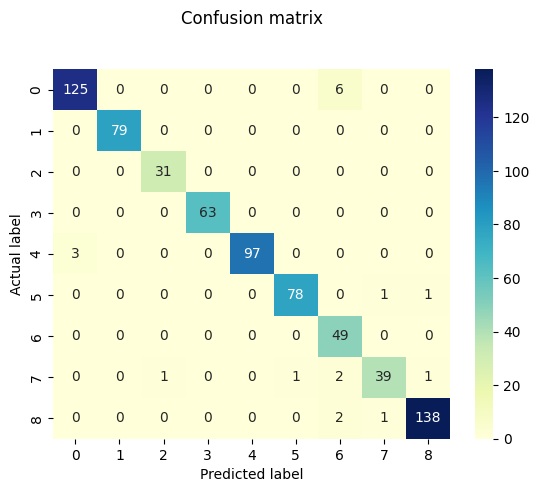

In [ ]:
#Making the Confusion Matrix
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_true, y_pred)
target_names = ['0', '1', '2', '3', '4', '5', '6', '7', '8']
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
p = sns.heatmap(pd.DataFrame(cm), annot=True,xticklabels=target_names, yticklabels=target_names, cmap="YlGnBu" ,fmt='g')
plt.title('Confusion matrix', y=1.1)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.savefig('/content/drive/MyDrive/pdfs/ct2_Task_CM.pdf')

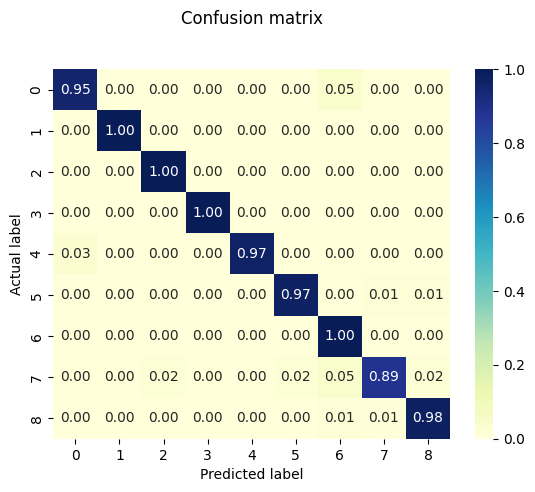

In [ ]:
#Making the Confusion Matrix
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_true, y_pred)
target_names = ['0', '1', '2', '3', '4', '5', '6', '7', '8']
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
cm = cm.astype('float')/cm.sum(axis=1)[:, np.newaxis]
p = sns.heatmap(pd.DataFrame(cm), annot=True,xticklabels=target_names, yticklabels=target_names, cmap="YlGnBu" ,fmt='.2f')
plt.title('Confusion matrix', y=1.1)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.savefig('/content/drive/MyDrive/pdfs/ct2_Task_NCM.pdf')

# **Classification Report**

In [ ]:
#import classification_report
from sklearn.metrics import classification_report
print(classification_report(y_true,y_pred, target_names = target_names))

              precision    recall  f1-score   support

           0       0.98      0.95      0.97       131
           1       1.00      1.00      1.00        79
           2       0.97      1.00      0.98        31
           3       1.00      1.00      1.00        63
           4       1.00      0.97      0.98       100
           5       0.99      0.97      0.98        80
           6       0.83      1.00      0.91        49
           7       0.95      0.89      0.92        44
           8       0.99      0.98      0.98       141

    accuracy                           0.97       718
   macro avg       0.97      0.97      0.97       718
weighted avg       0.98      0.97      0.97       718



# **ROC Curve**

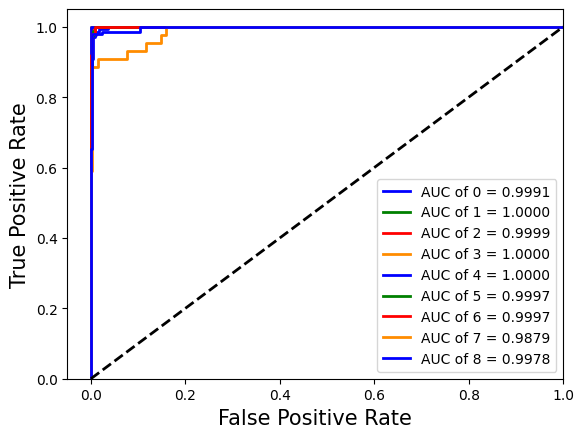

In [ ]:
from sklearn.metrics import roc_curve, auc
from itertools import cycle
fpr = dict()
tpr = dict()
roc_auc = dict()
lw=2
for i in range(9):
    fpr[i], tpr[i], _ = roc_curve(y_test[:, i], pred[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
colors =cycle(['blue', 'green', 'red','darkorange'])
for i, color in zip(range(9), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label='AUC of {0} = {1:0.4f}'
             ''.format(i, roc_auc[i]))
plt.plot([0, 1], [0, 1], 'k--', lw=lw)
plt.xlim([-0.05, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate',fontsize=15)
plt.ylabel('True Positive Rate',fontsize=15)
plt.legend(loc="lower right")
plt.savefig('/content/drive/MyDrive/pdfs/ct2_Task_ROC.pdf')
plt.show()

In [ ]:
np.save('/content/drive/MyDrive/fpr-tpr_files/ct2_fpr_task.npy', fpr)
np.save('/content/drive/MyDrive/fpr-tpr_files/ct2_tpr_task.npy', tpr)

# **Model Size, FLOPS, and MACS**

In [ ]:
import tensorflow as tf
from tensorflow import keras

# Calculate FLOPs and MACs
flops = 0
macs = 0

for layer in model.layers:
    if isinstance(layer, keras.layers.Conv2D):
        # Get layer parameters
        filters = layer.filters
        kernel_size = layer.kernel_size
        strides = layer.strides
        input_shape = layer.input_shape[1:]

        # Calculate FLOPs
        flops += 2 * np.prod(input_shape) * filters * np.prod(kernel_size) / np.prod(strides)

        # Calculate MACs
        macs += np.prod(input_shape) * filters * np.prod(kernel_size) / np.prod(strides)

    elif isinstance(layer, keras.layers.Dense):
        # Get layer parameters
        units = layer.units
        input_shape = layer.input_shape[1:]

        # Calculate FLOPs
        flops += 2 * np.prod(input_shape) * units

        # Calculate MACs
        macs += np.prod(input_shape) * units

print("FLOPs:", flops)
print("MACs:", macs)
# Convert FLOPs to GFLOPs
flops_in_giga = flops / 1e9

# Convert MACs to GMACs
macs_in_giga = macs / 1e9

print("GFLOPs:", flops_in_giga)
print("GMACs:", macs_in_giga)

FLOPs: 138974233728.0
MACs: 69487116864.0
GFLOPs: 138.974233728
GMACs: 69.487116864


In [ ]:
# Calculate model size in MB
model_size = model.count_params() * 4 / (1024 * 1024)  # Assuming float32 precision
print("Model Size (MB):", model_size)

Model Size (MB): 20.56082534790039


# **Trained Feature Visualization**

In [14]:
from keras.models import Model
model = model
layer_name = 'dense_6'
intermediate_layer_model = Model(inputs = model.input, outputs = model.get_layer(layer_name).output)
intermediate_output1 = intermediate_layer_model.predict([X_test])

23/23 [==============================] - 2036s 87s/step


In [15]:
import numpy as np
import pandas as pd
np.savetxt("/content/drive/MyDrive/feature_files/ct_dataset_2_X_test_Proposed_Features.csv", intermediate_output1, delimiter = ",")

In [16]:
df2 = pd.read_csv("/content/drive/MyDrive/feature_files/ct_dataset_2_X_test_Proposed_Features.csv", header = None, delimiter = ",")
df2

,0,1,2,3,4,5,6,7,8,9,...,54,55,56,57,58,59,60,61,62,63
0,0.292302,0.000000,0.328399,0.000000,2.818614,0.267674,0.149013,0.0,2.538942,1.388751,...,3.215119,1.839718,3.105380,0.893066,1.004563,0.000000,3.117979,0.386422,2.195273,0.316005
1,0.000000,0.052557,0.000000,0.000000,9.545742,7.341027,4.745128,0.0,0.989559,0.000000,...,5.756227,10.507324,5.784803,4.751214,0.000000,0.395618,0.000000,0.000000,0.835579,12.278620
2,3.630110,0.000000,0.882756,0.319677,2.617467,1.242872,0.000000,0.0,1.412081,0.280145,...,0.000000,0.337583,0.333379,5.069033,1.950296,1.874463,0.902287,1.089454,0.000000,0.000000
3,2.053702,2.162667,0.866363,2.043764,0.162400,2.892128,0.000000,0.0,1.463317,2.837115,...,0.279988,1.194394,0.000000,3.678673,3.451213,4.320251,1.489197,2.356139,0.261975,2.061277
4,0.724873,3.863691,0.689030,0.729984,0.000000,2.660465,2.268724,0.0,0.998147,1.717898,...,2.001077,0.515868,0.831904,2.751221,4.728896,6.411613,0.000000,4.726446,0.000000,1.539323
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
713,0.000000,0.000000,0.021553,0.000000,3.731270,0.554525,0.392329,0.0,2.983773,0.993223,...,3.923665,2.561797,3.930765,1.042197,0.383453,0.000000,3.232136,0.256366,2.530518,0.770864
714,0.551335,2.145162,0.303662,2.614198,1.544914,3.502525,0.000000,0.0,1.628449,2.324336,...,0.708129,2.170946,0.000000,3.603555,1.696651,2.812142,1.483966,0.583084,0.000000,4.105859
715,1.088117,2.702723,0.000000,2.859982,0.000000,1.041405,3.868375,0.0,0.298874,3.475500,...,0.181883,0.000000,1.992826,0.000000,4.948376,4.195247,0.617743,2.638759,2.896373,3.826970
716,1.017420,2.660620,1.188518,4.794769,0.825187,3.135389,0.000000,0.0,2.451439,4.413353,...,0.000000,1.277551,0.000000,4.472180,1.945358,2.559861,2.664034,0.000000,0.232609,4.070431


In [17]:
import numpy as np
from sklearn.manifold import TSNE
X = np.array(df2)
X_embedded = TSNE(n_components=2).fit_transform(X)

In [18]:
df3 = pd.read_csv("/content/drive/MyDrive/feature_files/ct_dataset_2_y_test.csv", header = None,  delimiter = ",")
df3.head()

,0
0,1.0
1,3.0
2,7.0
3,8.0
4,6.0


In [19]:
import plotly.express as px
fig = px.scatter(X_embedded, x =0, y = 1, color=df3[0], width=600, height=500)
fig.show()

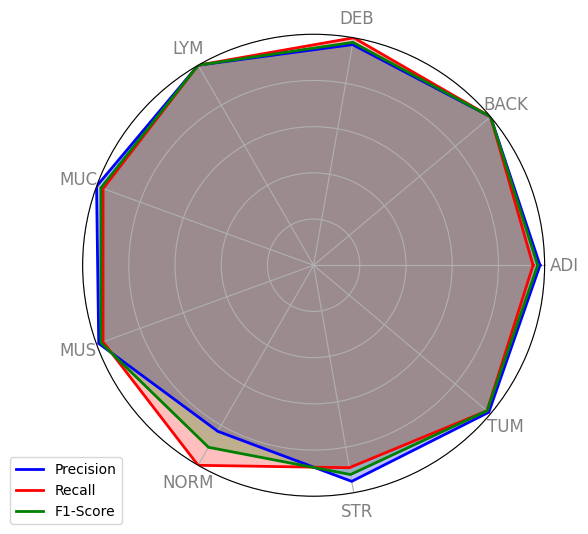

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from math import pi

# Define the metrics and their values
labels = ['ADI', 'BACK', 'DEB', 'LYM', 'MUC', 'MUS', 'NORM', 'STR', 'TUM']
precision = [0.98, 1.00, 0.97, 1.00, 1.00, 0.99, 0.83, 0.95, 0.99]
recall = [0.95, 1.00, 1.00, 1.00, 0.97, 0.97, 1.00, 0.89, 0.98]
f1_score = [0.97, 1.00, 0.98, 1.00, 0.98, 0.98, 0.91, 0.92, 0.98]

# Combine metrics into a single list of lists
metrics = [precision, recall, f1_score]
metrics_labels = ['Precision', 'Recall', 'F1-Score']
colors = ['b', 'r', 'g']  # Colors for each metric

# Number of variables
num_vars = len(labels)

# Compute angle of each axis
angles = [n / float(num_vars) * 2 * pi for n in range(num_vars)]
angles += angles[:1]  # Repeat the first angle to close the circle

# Initialize the radar chart
fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))
ax.set_facecolor('white')

# Draw one axe per variable and add labels
plt.xticks(angles[:-1], labels, color='grey', size=12)

# Draw y-labels
ax.set_yticklabels([])  # Remove the numeric values
ax.set_ylim(0.0, 1.0)

# Plot data
for metric, label, color in zip(metrics, metrics_labels, colors):
    values = metric + metric[:1]
    ax.plot(angles, values, linewidth=2, linestyle='solid', label=label, color=color)
    ax.fill(angles, values, color=color, alpha=0.25)

# Add title
# plt.title('Dataset 2', size=10, color='black', y=1.1)

# Add a legend
plt.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))

# Show the plot
plt.show()
